# Task 3 – Models: Supervised and Unsupervised

Run all cells from top to bottom. This notebook includes its own imports, synthetic dataset, and train/validation/test split setup.

# Week 2 – Weekly Assessment: Machine Learning
**YOHO Technologies | Loan Applicants Scenario**

This notebook completes Tasks 1–4 using one reproducible synthetic bank-loan dataset. Run cells from top to bottom. The test set is kept aside until the final evaluation in Task 4.

In [ ]:
import warnings, os, joblib
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, GridSearchCV, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, roc_curve, roc_auc_score,
                             mean_absolute_error, mean_squared_error, r2_score,
                             silhouette_score)
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression, LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.cluster import KMeans

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
print("Libraries imported successfully.")

Libraries imported successfully.


In [ ]:
# Reproducible stratified cross-validation splitter shared by tasks.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


In [ ]:
# Compatibility helper for scikit-learn versions before/after sparse_output rename.
def make_onehot():
    try:
        return OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    except TypeError:
        return OneHotEncoder(handle_unknown="ignore", sparse=False)


## 0. Dataset Generation – Bank Loan Applicants

In [ ]:
n_samples = 2000
rng = np.random.default_rng(RANDOM_STATE)

applicant_ids = np.arange(1001, 1001 + n_samples)
dates = pd.date_range("2024-01-01", periods=n_samples, freq="4h")
age = rng.integers(21, 66, n_samples)
annual_income = rng.lognormal(mean=10.8, sigma=0.6, size=n_samples)
loan_amount = np.clip(annual_income * rng.uniform(0.15, 0.65, n_samples) + rng.normal(0, 5000, n_samples), 5000, 150000)
credit_score = np.clip(rng.normal(670, 60, n_samples), 300, 850)
debt_to_income = np.clip((loan_amount * 0.12) / annual_income + rng.normal(0.15, 0.05, n_samples), 0.01, 0.95)
education = rng.choice(["High School", "Bachelor", "Master", "PhD"], n_samples, p=[0.30, 0.45, 0.20, 0.05])
employment = rng.choice(["Salaried", "Self-Employed", "Business", "Unemployed"], n_samples, p=[0.55, 0.25, 0.15, 0.05])
property_area = rng.choice(["Urban", "Semiurban", "Rural"], n_samples, p=[0.40, 0.35, 0.25])

# A synthetic probability of default, used only to create a realistic target.
logit = (-2.2 + 3.0 * debt_to_income - 0.006 * (credit_score - 650)
         + 0.45 * (employment == "Unemployed")
         + 0.25 * (employment == "Self-Employed")
         + 0.18 * (education == "High School"))
prob_default = 1 / (1 + np.exp(-logit))
default = rng.binomial(1, prob_default)

df = pd.DataFrame({
    "Applicant_ID": applicant_ids,
    "Application_Date": dates,
    "Age": age,
    "Annual_Income": annual_income,
    "Loan_Amount": loan_amount,
    "Credit_Score": credit_score,
    "Debt_to_Income": debt_to_income,
    "Education_Level": education,
    "Employment_Type": employment,
    "Property_Area": property_area,
    "Default": default
})

# Add missing values to demonstrate imputation.
for col in ["Annual_Income", "Credit_Score", "Employment_Type"]:
    missing_idx = rng.choice(df.index, size=int(0.03 * n_samples), replace=False)
    df.loc[missing_idx, col] = np.nan

print("Dataset shape:", df.shape)
print("Default rate:", round(df["Default"].mean(), 3))
display(df.head())

Dataset shape: (2000, 11)
Default rate: 0.18


,Applicant_ID,Application_Date,Age,Annual_Income,Loan_Amount,Credit_Score,Debt_to_Income,Education_Level,Employment_Type,Property_Area,Default
0,1001,2024-01-01 00:00:00,25,31403.817584,21781.751722,572.221835,0.286323,PhD,Salaried,Rural,0
1,1002,2024-01-01 04:00:00,55,85358.443759,39681.941286,619.451077,0.197838,Bachelor,Salaried,Urban,0
2,1003,2024-01-01 08:00:00,50,50049.466458,5000.000000,655.786146,0.190497,Bachelor,Salaried,Rural,0
3,1004,2024-01-01 12:00:00,40,41370.467114,9761.351215,644.974706,0.205203,Bachelor,Salaried,Urban,0
4,1005,2024-01-01 16:00:00,40,45995.131901,22921.204864,650.034598,0.199029,Bachelor,Salaried,Urban,0


## Shared feature engineering and train/validation/test split

In [ ]:
def add_features(data):
    data = data.copy()
    dates = pd.to_datetime(data["Application_Date"])
    data["Application_Month"] = dates.dt.month
    data["Application_Day"] = dates.dt.day
    data["Income_to_Loan"] = data["Annual_Income"] / data["Loan_Amount"].replace(0, np.nan)
    data["Log_Annual_Income"] = np.log1p(data["Annual_Income"].clip(lower=0))
    return data

df_features = add_features(df)
target = "Default"
drop_cols = ["Applicant_ID", "Application_Date", target]
X = df_features.drop(columns=drop_cols)
y = df_features[target].astype(int)

# First split: 60% train+validation, 40% test; then split remaining into 60/20 overall.
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.25, random_state=RANDOM_STATE, stratify=y_train_val
)
print(f"Train: {len(X_train)} ({len(X_train)/len(X):.0%})")
print(f"Validation: {len(X_val)} ({len(X_val)/len(X):.0%})")
print(f"Test: {len(X_test)} ({len(X_test)/len(X):.0%}) — kept aside until Task 4")

Train: 1200 (60%)
Validation: 400 (20%)
Test: 400 (20%) — kept aside until Task 4


In [ ]:
# Shared column lists used by all task notebooks.
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=np.number).columns.tolist()


## Task 3 – Supervised and Unsupervised Models

In [ ]:
# Train four classifiers in pipelines; validation data is used for model comparison.
def build_preprocessor():
    return ColumnTransformer([
        ("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                          ("scaler", StandardScaler())]), numeric_features),
        ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                          ("onehot", make_onehot())]), categorical_features)
    ])

classifiers = {
    "LogisticRegression": LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    "DecisionTree": DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE),
    "RandomForest": RandomForestClassifier(n_estimators=150, random_state=RANDOM_STATE,
                                           oob_score=True, bootstrap=True, n_jobs=-1)
}

try:
    from xgboost import XGBClassifier
    xgb_available = True
    xgb_model = XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.05,
                              subsample=0.9, colsample_bytree=0.9,
                              eval_metric="logloss", random_state=RANDOM_STATE,
                              n_jobs=2)
except ImportError:
    xgb_available = False
    print("xgboost is not installed. Install with: pip install xgboost")

if xgb_available:
    classifiers["XGBoost"] = xgb_model

trained_models = {}
results = []
for name, estimator in classifiers.items():
    pipe = Pipeline([("preprocessor", build_preprocessor()), ("classifier", estimator)])
    pipe.fit(X_train, y_train)
    trained_models[name] = pipe
    pred = pipe.predict(X_val)
    score = accuracy_score(y_val, pred)
    results.append({"Model": name, "Validation accuracy": score})
    print(f"{name}: validation accuracy = {score:.3f}")
    if name == "RandomForest":
        print("Random Forest OOB score:", round(pipe.named_steps["classifier"].oob_score_, 3))

results_df = pd.DataFrame(results).sort_values("Validation accuracy", ascending=False)
display(results_df)

LogisticRegression: validation accuracy = 0.820
DecisionTree: validation accuracy = 0.812


RandomForest: validation accuracy = 0.818
Random Forest OOB score: 0.82
XGBoost: validation accuracy = 0.812


,Model,Validation accuracy
0,LogisticRegression,0.8200
2,RandomForest,0.8175
1,DecisionTree,0.8125
3,XGBoost,0.8125


In [ ]:
# XGBoost early-stopping demonstration on validation data (when installed).
if xgb_available:
    from sklearn.base import clone
    xgb_pre = build_preprocessor()
    Xtr_xgb = xgb_pre.fit_transform(X_train)
    Xva_xgb = xgb_pre.transform(X_val)
    xgb_es = XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.05,
                           subsample=0.9, colsample_bytree=0.9, eval_metric="logloss",
                           random_state=RANDOM_STATE, n_jobs=2, early_stopping_rounds=20)
    try:
        xgb_es.fit(Xtr_xgb, y_train, eval_set=[(Xva_xgb, y_val)], verbose=False)
        print("XGBoost early stopping best iteration:", getattr(xgb_es, "best_iteration", "not reported"))
    except TypeError:
        print("This XGBoost version does not accept early_stopping_rounds in the constructor;")
        print("the tuned XGBoost pipeline below is still trained and evaluated.")
else:
    print("Skipping XGBoost early stopping because xgboost is unavailable.")

XGBoost early stopping best iteration: 29


In [ ]:
# Logistic regression probabilities for 5 validation rows.
lr_pipe = trained_models["LogisticRegression"]
print("predict_proba (first 5 rows):")
print(lr_pipe.predict_proba(X_val.head(5)))
print("predict (first 5 rows):", lr_pipe.predict(X_val.head(5)))

# Top 5 feature importances from Random Forest and XGBoost (if available).
def show_top_features(pipe, title):
    fitted_pre = pipe.named_steps["preprocessor"]
    clf = pipe.named_steps["classifier"]
    try:
        names = fitted_pre.get_feature_names_out()
        importances = clf.feature_importances_
        top = pd.Series(importances, index=names).sort_values(ascending=False).head(5)
        print(title)
        display(top.to_frame("importance"))
    except Exception as exc:
        print(title, "feature importance unavailable:", exc)

show_top_features(trained_models["RandomForest"], "Random Forest – top 5 features")
if xgb_available:
    show_top_features(trained_models["XGBoost"], "XGBoost – top 5 features")

predict_proba (first 5 rows):
[[0.76410249 0.23589751]
 [0.79794228 0.20205772]
 [0.8510619  0.1489381 ]
 [0.77192326 0.22807674]
 [0.83309872 0.16690128]]
predict (first 5 rows): [0 0 0 0 0]
Random Forest – top 5 features


,importance
num__Credit_Score,0.138907
num__Debt_to_Income,0.109986
num__Income_to_Loan,0.100229
num__Annual_Income,0.097061
num__Log_Annual_Income,0.094776


XGBoost – top 5 features


,importance
num__Credit_Score,0.075439
cat__Employment_Type_Self-Employed,0.073027
cat__Property_Area_Urban,0.071592
num__Log_Annual_Income,0.062237
cat__Education_Level_Bachelor,0.056678


In [ ]:
# Regression: predict loan amount. Use train/validation rows only; test remains untouched.
reg_target = "Loan_Amount"
X_reg = df_features.drop(columns=["Applicant_ID", "Application_Date", "Default", reg_target])
y_reg = df_features[reg_target]
Xr_train, Xr_val, yr_train, yr_val = train_test_split(
    X_reg, y_reg, test_size=0.20, random_state=RANDOM_STATE
)
reg_num = Xr_train.select_dtypes(include=np.number).columns.tolist()
reg_cat = Xr_train.select_dtypes(exclude=np.number).columns.tolist()
reg_pre = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), reg_num),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("onehot", make_onehot())]), reg_cat)
])
reg_models = {
    "LinearRegression": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "Lasso": Lasso(alpha=0.01, max_iter=10000)
}
reg_results = {}
for name, estimator in reg_models.items():
    pipe = Pipeline([("preprocessor", reg_pre), ("regressor", estimator)])
    pipe.fit(Xr_train, yr_train)
    pred = pipe.predict(Xr_val)
    reg_results[name] = pipe
    print(f"{name}: MAE={mean_absolute_error(yr_val, pred):.2f}, R2={r2_score(yr_val, pred):.3f}")
lasso_coef = reg_results["Lasso"].named_steps["regressor"].coef_
print("Lasso zero coefficients:", int(np.sum(np.isclose(lasso_coef, 0))))

LinearRegression: MAE=5079.71, R2=0.800
Ridge: MAE=5079.44, R2=0.800


Lasso: MAE=5079.70, R2=0.800
Lasso zero coefficients: 2


k=2: silhouette=0.435


k=3: silhouette=0.323


k=4: silhouette=0.325


k=5: silhouette=0.289


k=6: silhouette=0.289


k=7: silhouette=0.288


k=8: silhouette=0.276


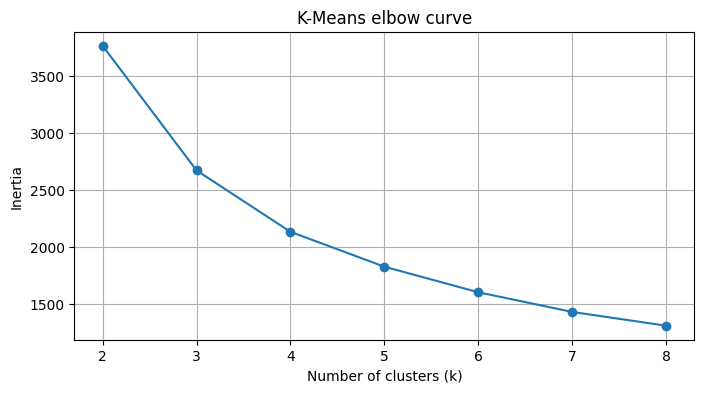

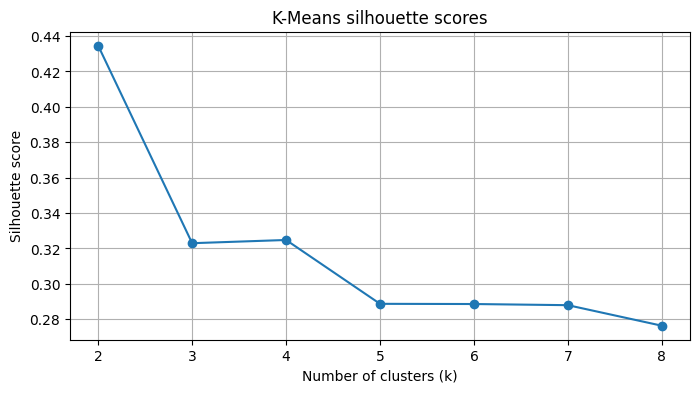

Selected k by highest silhouette: 2


,Annual_Income,Loan_Amount,Credit_Score
Segment,,,
0,43348.41,16474.80,672.16
1,112360.77,49636.74,661.05


In [ ]:
# K-Means for k=2..8 using two/three numeric columns.
cluster_cols = ["Annual_Income", "Loan_Amount", "Credit_Score"]
cluster_data = df_features[cluster_cols].copy()
cluster_data = SimpleImputer(strategy="median").fit_transform(cluster_data)
cluster_data = StandardScaler().fit_transform(cluster_data)

ks = range(2, 9)
inertias, silhouettes = [], []
for k in ks:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = km.fit_predict(cluster_data)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(cluster_data, labels))
    print(f"k={k}: silhouette={silhouettes[-1]:.3f}")

fig, ax1 = plt.subplots(figsize=(8, 4))
ax1.plot(list(ks), inertias, marker="o")
ax1.set_xlabel("Number of clusters (k)")
ax1.set_ylabel("Inertia")
ax1.set_title("K-Means elbow curve")
ax1.grid(True)
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(list(ks), silhouettes, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Silhouette score")
plt.title("K-Means silhouette scores")
plt.grid(True)
plt.show()

best_k = list(ks)[int(np.argmax(silhouettes))]
best_kmeans = KMeans(n_clusters=best_k, random_state=RANDOM_STATE, n_init=10)
cluster_labels = best_kmeans.fit_predict(cluster_data)
print("Selected k by highest silhouette:", best_k)
segment_summary = df.assign(Segment=cluster_labels).groupby("Segment")[cluster_cols].mean().round(2)
display(segment_summary)